# MMA3001 Project - Ellena Glenk

## Setup


### Install Libraries

In [53]:
# Install libraries
!pip install -q open3d

# Standard Python libraries
import os
import re
import zipfile
import shutil
import subprocess
from pathlib import Path
from collections import defaultdict

# Numerical/data libraries
import numpy as np
import pandas as pd

# Image processing
from PIL import Image
import matplotlib.pyplot as plt

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 3D processing
import open3d as o3d

# Display plots inside the notebook
%matplotlib inline

import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from PIL import Image

# GitHub
from google.colab import userdata
from google.colab import drive
import tempfile
import shutil

print("Libraries loaded successfully.")

Libraries loaded successfully.


### Setup GitHub

In [2]:
# ============================================================
# GITHUB CONFIGURATION
# ============================================================

# Replace these with your GitHub details
GITHUB_USERNAME = "ellenaglenk"
GITHUB_REPO = "MMA3001_Project_34957189"

# Use the same email associated with your GitHub account
GITHUB_EMAIL = "egle0003@student.monash.edu"

# Configure Git author information
subprocess.run(
    ["git", "config", "--global", "user.name", GITHUB_USERNAME],
    check=True
)

subprocess.run(
    ["git", "config", "--global", "user.email", GITHUB_EMAIL],
    check=True
)

# Repository directory in Colab
REPO_DIR = Path("/content") / GITHUB_REPO

print("Git configuration complete!")
print("Repository directory:", REPO_DIR)

Git configuration complete!
Repository directory: /content/MMA3001_Project_34957189


In [3]:
# ============================================================
# CONNECT COLAB TO GITHUB
# ============================================================

# Retrieve the token securely from Colab Secrets
github_token = userdata.get("GITHUB_TOKEN")

if not github_token:
    raise ValueError("GITHUB_TOKEN was not found in Colab Secrets.")

# Git authentication without including the token in the URL
askpass_dir = tempfile.TemporaryDirectory()
askpass_path = Path(askpass_dir.name) / "git_askpass.sh"

askpass_path.write_text(
    '#!/bin/sh\n'
    'case "$1" in\n'
    '  *Username*) printf "%s\\n" "x-access-token" ;;\n'
    '  *Password*) printf "%s\\n" "$GITHUB_TOKEN" ;;\n'
    'esac\n'
)

askpass_path.chmod(0o700)

git_env = os.environ.copy()
git_env["GITHUB_TOKEN"] = github_token
git_env["GIT_ASKPASS"] = str(askpass_path)
git_env["GIT_TERMINAL_PROMPT"] = "0"

# Clone the repository if it is not already present
repo_url = (
    f"https://github.com/{GITHUB_USERNAME}/{GITHUB_REPO}.git"
)

if not (REPO_DIR / ".git").exists():
    subprocess.run(
        ["git", "clone", repo_url, str(REPO_DIR)],
        check=True,
        env=git_env
    )

print("GitHub repository connected!")
print("Local repository:", REPO_DIR)

GitHub repository connected!
Local repository: /content/MMA3001_Project_34957189


In [8]:
# ============================================================
# LOCATE NOTEBOOK IN GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

# Change this if your notebook is in a Drive subfolder
NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/MMA3001_Assignment.ipynb"
)

print("Notebook found:", NOTEBOOK_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Notebook found: True


In [10]:
# ============================================================
# SAVE AND COMMIT NOTEBOOK TO GITHUB
# ============================================================

def commit_to_github(message):
    """
    Commit the latest saved Colab notebook to GitHub.

    Parameters
    ----------
    message : str
        A description of the changes being committed.
    """

    # Check that the notebook exists in Google Drive
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError(
            f"Notebook not found: {NOTEBOOK_PATH}"
        )

    # Copy the notebook into the GitHub repository
    destination = REPO_DIR / NOTEBOOK_PATH.name

    shutil.copy2(NOTEBOOK_PATH, destination)

    # Stage only the notebook (not the dataset or secrets)
    subprocess.run(
        ["git", "add", "--", destination.name],
        cwd=REPO_DIR,
        check=True
    )

    # Check whether there are changes to commit
    changes = subprocess.run(
        ["git", "diff", "--cached", "--quiet"],
        cwd=REPO_DIR
    )

    if changes.returncode == 0:
        print("No new changes to commit.")
        return

    if changes.returncode != 1:
        raise RuntimeError("Unable to check staged changes.")

    # Create a Git commit
    subprocess.run(
        ["git", "commit", "-m", message],
        cwd=REPO_DIR,
        check=True
    )

    # Push changes to GitHub
    subprocess.run(
        ["git", "push", "origin", "HEAD"],
        cwd=REPO_DIR,
        env=git_env,
        check=True
    )

    print("Successfully committed and pushed to GitHub!")
    print("Commit message:", message)

In [11]:
# ============================================================
# COMMIT CURRENT CHANGES TO GITHUB
# ============================================================

commit_to_github("Completed setup and GitHub connection.")

Successfully committed and pushed to GitHub!
Commit message: Completed setup and GitHub connection.


## Import, Extraction and Analysis of Data

### Upload Zip File from Connected Google Drive

In [15]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

print("Google Drive connected successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!


In [16]:
from pathlib import Path

# Google Drive ZIP path
zip_path = Path(
    "/content/drive/MyDrive/2026/Tree_Dataset_SummerGT.zip"
)

# Check that the file exists
if not zip_path.is_file():
    raise FileNotFoundError(
        f"ZIP file not found: {zip_path}"
    )

print("Dataset found successfully!")
print("File:", zip_path.name)
print("Size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")

Dataset found successfully!
File: Tree_Dataset_SummerGT.zip
Size: 735.57 MB


### Extract the ZIP File

In [17]:
import zipfile
from pathlib import Path

# Location of your ZIP file in Google Drive
zip_path = Path("/content/drive/MyDrive/2026/Tree_Dataset_SummerGT.zip")

# Location where the extracted images will be stored
dataset_dir = Path("/content/tree_dataset")

# Check that the ZIP file exists
if not zip_path.exists():
    raise FileNotFoundError(
        f"ZIP file not found: {zip_path}\n"
        "Make sure Google Drive is mounted."
    )

# Create extraction folder
dataset_dir.mkdir(parents=True, exist_ok=True)

# Check whether the ZIP file is valid
if not zipfile.is_zipfile(zip_path):
    raise ValueError("The selected file is not a valid ZIP archive.")

# Extract all files
print("Extracting dataset. This may take a few minutes...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(dataset_dir)

print("Dataset extracted successfully!")
print("Extracted to:", dataset_dir)

Extracting dataset. This may take a few minutes...
Dataset extracted successfully!
Extracted to: /content/tree_dataset


### Check Extracted Images

In [18]:
image_extensions = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

image_files = [
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_files))

print("\nFirst 20 filenames:")
for path in image_files[:20]:
    print(path.name)

Total images found: 2810

First 20 filenames:
R13N18_Winter_RGB-12-56-21.png
R11N06_Winter_D-12-14-39.png
R02N04_Summer_RGB-12-49-27.png
R16N10_Winter_RGB-13-10-07.png
R02N39_Winter_D-11-33-35.png
R05N30_Summer_GT-13-12-46.png
R17N18_Summer_RGB-14-11-52.png
R11N01_Winter_D-12-14-17.png
R06N26_Summer_D-13-18-12.png
R02N26_Winter_D-11-32-28.png
R03N31_Summer_RGB-13-0-42.png
R14N03_Winter_D-12-59-49.png
R11N19_Summer_D-13-42-51.png
R16N10_Winter_D-13-10-07.png
R06N19_Winter_D-11-53-06.png
R05N19_Winter_D-11-48-16.png
R02N03_Summer_D-12-49-23.png
R17N05_Summer_D-14-10-43.png
R12N20_Summer_GT-13-46-34.png
R08N04_Summer_D-13-26-13.png


### Inspect Dataset

In [19]:
# Inspect filenames
image_extensions = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

image_files = [
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print(f"Total image files found: {len(image_files)}")

# Print the first 30 filenames
for path in image_files[:30]:
    print(path.name)



# Inspect and show directories containing data
directories = sorted(set(path.parent for path in image_files))

print(f"Number of image directories: {len(directories)}")

for directory in directories[:30]:
    print(directory)

Total image files found: 2810
R13N18_Winter_RGB-12-56-21.png
R11N06_Winter_D-12-14-39.png
R02N04_Summer_RGB-12-49-27.png
R16N10_Winter_RGB-13-10-07.png
R02N39_Winter_D-11-33-35.png
R05N30_Summer_GT-13-12-46.png
R17N18_Summer_RGB-14-11-52.png
R11N01_Winter_D-12-14-17.png
R06N26_Summer_D-13-18-12.png
R02N26_Winter_D-11-32-28.png
R03N31_Summer_RGB-13-0-42.png
R14N03_Winter_D-12-59-49.png
R11N19_Summer_D-13-42-51.png
R16N10_Winter_D-13-10-07.png
R06N19_Winter_D-11-53-06.png
R05N19_Winter_D-11-48-16.png
R02N03_Summer_D-12-49-23.png
R17N05_Summer_D-14-10-43.png
R12N20_Summer_GT-13-46-34.png
R08N04_Summer_D-13-26-13.png
R05N33_Summer_GT-13-13-9.png
R04N18_Summer_D-13-7-5.png
R10N04_Summer_D-13-36-22.png
R05N10_Summer_GT-13-10-52.png
R06N26_Winter_D-11-53-42.png
R06N24_Summer_GT-13-18-1.png
R01N33_Summer_RGB-12-44-58.png
R13N33_Winter_D-12-57-32.png
R01N42_Summer_D-12-46-12.png
R01N27_Winter_RGB-11-26-03.png
Number of image directories: 1
/content/tree_dataset/Dataset (With Summer GT)


### Inspect Image Dimensions and Pixel Values

In [20]:
def inspect_image(path):
    """
    Print basic information about an image.

    Parameters
    ----------
    path : Path
        Path to the image.
    """

    image = Image.open(path)
    array = np.array(image)

    print(f"\nFile: {path.name}")
    print(f"Format: {image.format}")
    print(f"Mode: {image.mode}")
    print(f"Size: {image.size}")
    print(f"Array shape: {array.shape}")
    print(f"Data type: {array.dtype}")
    print(f"Minimum pixel value: {array.min()}")
    print(f"Maximum pixel value: {array.max()}")


# Inspect the first few images
for path in image_files[:10]:
    inspect_image(path)


File: R13N18_Winter_RGB-12-56-21.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 1
Maximum pixel value: 255

File: R11N06_Winter_D-12-14-39.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 159

File: R02N04_Summer_RGB-12-49-27.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255

File: R16N10_Winter_RGB-13-10-07.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 1
Maximum pixel value: 255

File: R02N39_Winter_D-11-33-35.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 139

File: R05N30_Summer_GT-13-12-46.png
Format: PNG
Mode: L
Size: (256, 256)
Array shape: (256, 256)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 

### Check Image Types, Pairs, Types etc

In [21]:
from pathlib import Path

# image_files was created in Step 6

rgb_files = []
depth_files = []
gt_files = []

for path in image_files:

    name = path.name.upper()

    if "_RGB-" in name:
        rgb_files.append(path)

    elif "_D-" in name:
        depth_files.append(path)

    elif "_GT-" in name:
        gt_files.append(path)

print("Dataset summary")
print("-------------------------")
print("RGB images:", len(rgb_files))
print("Depth images:", len(depth_files))
print("Ground truth images:", len(gt_files))

print("\nTotal classified:",
      len(rgb_files) + len(depth_files) + len(gt_files))

Dataset summary
-------------------------
RGB images: 1124
Depth images: 1124
Ground truth images: 562

Total classified: 2810


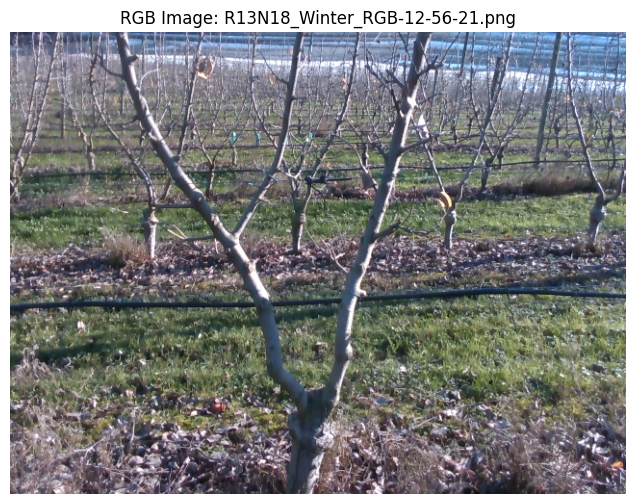

In [22]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Select the first RGB image
rgb_path = rgb_files[0]

rgb = np.array(Image.open(rgb_path))

plt.figure(figsize=(10, 6))

plt.imshow(rgb)

plt.title(f"RGB Image: {rgb_path.name}")
plt.axis("off")

plt.show()

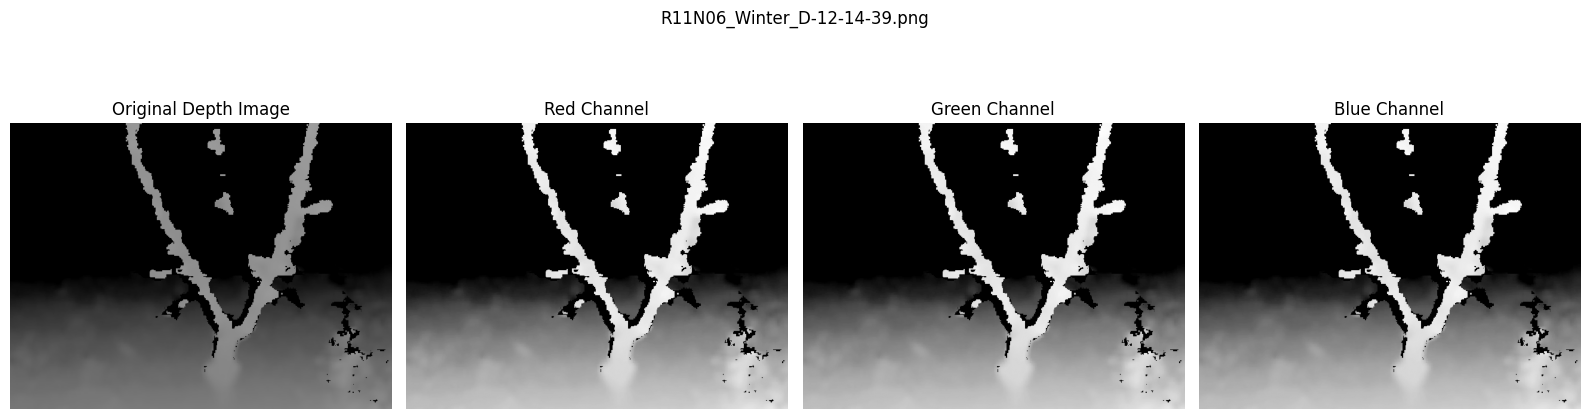

In [23]:
depth_path = depth_files[0]

depth = np.array(Image.open(depth_path))

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

# Original depth image
axes[0].imshow(depth)
axes[0].set_title("Original Depth Image")

# Individual colour channels
channels = ["Red", "Green", "Blue"]

for i in range(3):

    axes[i + 1].imshow(
        depth[:, :, i],
        cmap="gray"
    )

    axes[i + 1].set_title(f"{channels[i]} Channel")

for ax in axes:
    ax.axis("off")

plt.suptitle(depth_path.name)
plt.tight_layout()
plt.show()

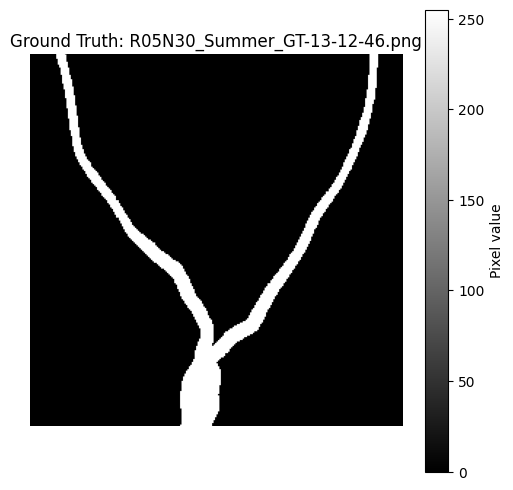

Image shape: (256, 256)
Unique pixel values: [  0 255]


In [24]:
gt_path = gt_files[0]

gt = np.array(Image.open(gt_path))

plt.figure(figsize=(6, 6))

plt.imshow(gt, cmap="gray", vmin=0, vmax=255)

plt.colorbar(label="Pixel value")

plt.title(f"Ground Truth: {gt_path.name}")
plt.axis("off")

plt.show()

print("Image shape:", gt.shape)
print("Unique pixel values:", np.unique(gt)[:30])

In [25]:
def get_observation_id(path):
    """
    Extract a common observation identifier by removing
    the RGB, D or GT label from the filename.
    """

    name = path.stem

    for label in ["_RGB-", "_D-", "_GT-"]:
        if label in name:
            return name.replace(label, "_")

    return None


# Create dictionaries of images
rgb_dict = {
    get_observation_id(p): p for p in rgb_files
}

depth_dict = {
    get_observation_id(p): p for p in depth_files
}

gt_dict = {
    get_observation_id(p): p for p in gt_files
}

# Find matching observations
rgb_depth_pairs = set(rgb_dict) & set(depth_dict)

complete_sets = (
    set(rgb_dict) &
    set(depth_dict) &
    set(gt_dict)
)

print("Matching RGB-depth pairs:", len(rgb_depth_pairs))
print("Complete RGB-depth-GT sets:", len(complete_sets))

Matching RGB-depth pairs: 1124
Complete RGB-depth-GT sets: 562


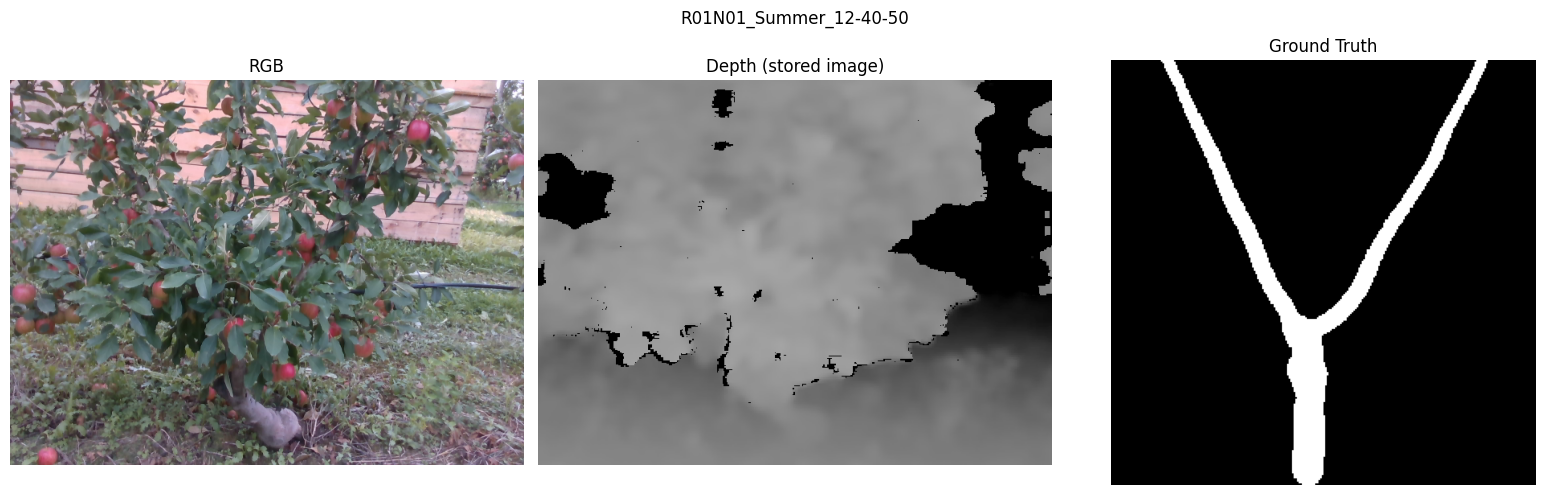

In [26]:
if len(complete_sets) > 0:

    observation = sorted(complete_sets)[0]

    rgb = np.array(Image.open(rgb_dict[observation]))
    depth = np.array(Image.open(depth_dict[observation]))
    gt = np.array(Image.open(gt_dict[observation]))

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].imshow(rgb)
    axes[0].set_title("RGB")

    axes[1].imshow(depth)
    axes[1].set_title("Depth (stored image)")

    axes[2].imshow(gt, cmap="gray")
    axes[2].set_title("Ground Truth")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(observation)
    plt.tight_layout()
    plt.show()

else:
    print("No complete RGB-depth-GT sets found.")
    print("The images may use different timestamps or naming conventions.")

In [27]:
import numpy as np
from PIL import Image

depth = np.array(Image.open(depth_files[0]))

# Compare the three channels
red = depth[:, :, 0]
green = depth[:, :, 1]
blue = depth[:, :, 2]

print("Red = Green:", np.array_equal(red, green))
print("Green = Blue:", np.array_equal(green, blue))

print("\nDepth values:")
print("Minimum:", depth.min())
print("Maximum:", depth.max())
print("Unique values:", len(np.unique(depth)))

Red = Green: True
Green = Blue: True

Depth values:
Minimum: 0
Maximum: 159
Unique values: 147


### Dataset Table

In [28]:
import pandas as pd
import re

records = []

# Loop through all observations with matching RGB and depth
for observation in sorted(rgb_depth_pairs):

    # Extract tree identifier and season
    match = re.match(
        r"(R\d+N\d+)_(Summer|Winter)_(.+)",
        observation,
        re.IGNORECASE
    )

    if match is None:
        print("Unrecognised filename:", observation)
        continue

    tree_id = match.group(1)
    season = match.group(2)
    timestamp = match.group(3)

    # Check whether a GT image exists
    has_gt = observation in gt_dict

    records.append({
        "observation_id": observation,
        "tree_id": tree_id,
        "season": season,
        "timestamp": timestamp,
        "rgb_path": str(rgb_dict[observation]),
        "depth_path": str(depth_dict[observation]),
        "gt_path": str(gt_dict[observation]) if has_gt else None,
        "has_gt": has_gt
    })

dataset = pd.DataFrame(records)

print("Dataset created successfully!")
print("Total observations:", len(dataset))
print("Unique trees:", dataset["tree_id"].nunique())

display(dataset.head())

# Save the table
dataset.to_csv(
    "/content/tree_dataset_metadata.csv",
    index=False
)

Dataset created successfully!
Total observations: 1124
Unique trees: 562


,observation_id,tree_id,season,timestamp,rgb_path,depth_path,gt_path,has_gt
0,R01N01_Summer_12-40-50,R01N01,Summer,12-40-50,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,True
1,R01N01_Winter_11-23-49,R01N01,Winter,11-23-49,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,None,False
2,R01N02_Summer_12-40-59,R01N02,Summer,12-40-59,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,True
3,R01N02_Winter_11-23-52,R01N02,Winter,11-23-52,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,None,False
4,R01N03_Summer_12-41-4,R01N03,Summer,12-41-4,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,True


## Seperate Training and Validation Data


### Split data 80/20

In [29]:
# Identify each unique physical tree
unique_trees = dataset["tree_id"].unique()

# Split trees into 80% training and 20% validation
train_trees, validation_trees = train_test_split(
    unique_trees,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# Select all observations belonging to training trees
train_data = dataset[
    dataset["tree_id"].isin(train_trees)
].copy()

# Select all observations belonging to validation trees
validation_data = dataset[
    dataset["tree_id"].isin(validation_trees)
].copy()

# Check that no tree appears in both datasets
overlap = set(train_trees) & set(validation_trees)

assert len(overlap) == 0, "Data leakage detected!"

print("Training and validation split successful!")
print("-----------------------------------------")

print("Training trees:", len(train_trees))
print("Validation trees:", len(validation_trees))

print("\nTraining observations:", len(train_data))
print("Validation observations:", len(validation_data))

print("\nOverlapping trees:", len(overlap))

Training and validation split successful!
-----------------------------------------
Training trees: 449
Validation trees: 113

Training observations: 898
Validation observations: 226

Overlapping trees: 0


### Check Ground Truth Distribution

In [30]:
print("Training dataset")
print("----------------")

print("Total observations:", len(train_data))
print("With ground truth:", train_data["has_gt"].sum())
print("Without ground truth:", (~train_data["has_gt"]).sum())

print("\nValidation dataset")
print("------------------")

print("Total observations:", len(validation_data))
print("With ground truth:", validation_data["has_gt"].sum())
print("Without ground truth:", (~validation_data["has_gt"]).sum())

# Check observations by season
print("\nTraining observations by season:")
print(train_data.groupby("season").size())

print("\nValidation observations by season:")
print(validation_data.groupby("season").size())

Training dataset
----------------
Total observations: 898
With ground truth: 449
Without ground truth: 449

Validation dataset
------------------
Total observations: 226
With ground truth: 113
Without ground truth: 113

Training observations by season:
season
Summer    449
Winter    449
dtype: int64

Validation observations by season:
season
Summer    113
Winter    113
dtype: int64


### Save Datasets

In [31]:
from pathlib import Path

# Create folder for processed data
processed_dir = Path("/content/processed_data")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save training metadata
train_data.to_csv(
    processed_dir / "train_metadata.csv",
    index=False
)

# Save validation metadata
validation_data.to_csv(
    processed_dir / "validation_metadata.csv",
    index=False
)

print("Dataset metadata saved successfully!")
print("Location:", processed_dir)

Dataset metadata saved successfully!
Location: /content/processed_data


## 2D Interpolation of Depth Images

### Inspect depth image values

Observation: R01N01_Summer_12-40-50
Depth image shape: (480, 640)
Minimum value: 0
Maximum value: 169
Unique values: 157
Zero-valued pixels: 36359
Percentage of zeros: 11.84 %


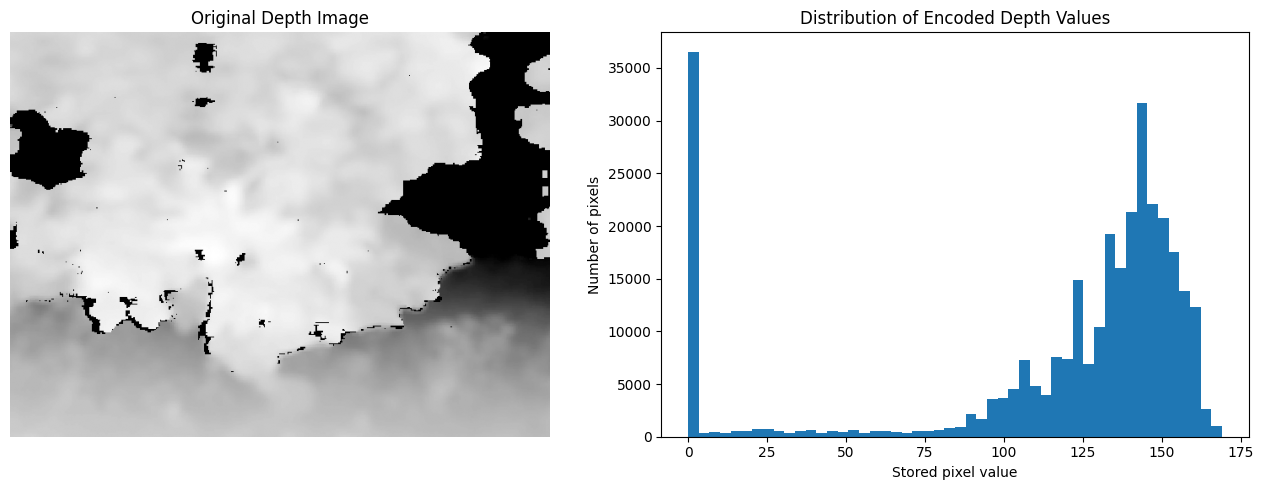

In [32]:
# Select a summer observation from the training dataset
example = train_data[
    (train_data["season"] == "Summer") &
    (train_data["has_gt"])
].iloc[0]

# Load the depth image
depth_image = Image.open(example["depth_path"]).convert("RGB")

# The three channels are identical, so use the first channel
depth = np.asarray(depth_image)[:, :, 0]

# Calculate basic statistics
print("Observation:", example["observation_id"])
print("Depth image shape:", depth.shape)
print("Minimum value:", depth.min())
print("Maximum value:", depth.max())
print("Unique values:", len(np.unique(depth)))
print("Zero-valued pixels:", np.sum(depth == 0))
print("Percentage of zeros:", round(np.mean(depth == 0) * 100, 2), "%")

# Display the depth image and its value distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(depth, cmap="gray")
axes[0].set_title("Original Depth Image")
axes[0].axis("off")

axes[1].hist(depth.ravel(), bins=50)
axes[1].set_title("Distribution of Encoded Depth Values")
axes[1].set_xlabel("Stored pixel value")
axes[1].set_ylabel("Number of pixels")

plt.tight_layout()
plt.show()

INTERPOLATION RESULTS
--------------------------------
Candidate valid pixels: 22410
Training pixels: 20169
Withheld test pixels: 2241
Linear coverage: 100.0 %

Nearest-neighbour RMSE (all test points): 0.6653
Nearest-neighbour RMSE (common points): 0.6653
Linear RMSE (common points): 0.4088


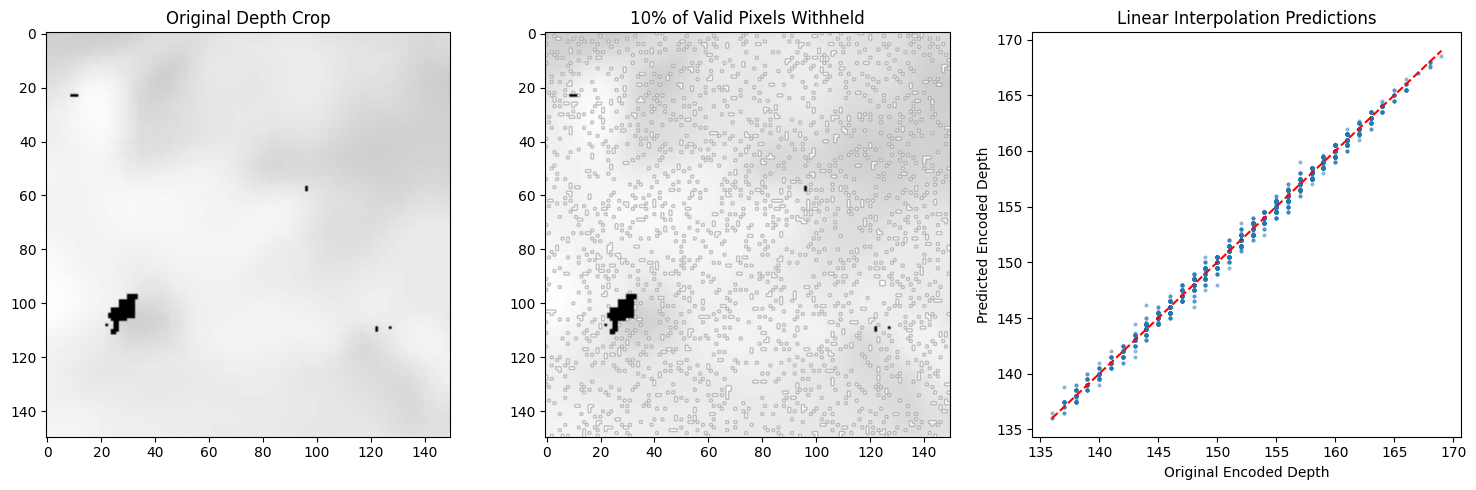

In [33]:

# Use the depth image loaded in Step 11.1
depth_float = depth.astype(np.float32)

# Select a central region to keep computation manageable
height, width = depth_float.shape

crop_size = 150

y_start = (height - crop_size) // 2
x_start = (width - crop_size) // 2

depth_crop = depth_float[
    y_start:y_start + crop_size,
    x_start:x_start + crop_size
]

# Identify nonzero pixels as candidate valid measurements
# Note: This is a working assumption for this experiment.
valid_mask = depth_crop > 0

# Create coordinate grids
yy, xx = np.indices(depth_crop.shape)

# Extract coordinates and values of candidate valid pixels
valid_points = np.column_stack((
    xx[valid_mask],
    yy[valid_mask]
))

valid_values = depth_crop[valid_mask]

# Randomly withhold 10% of the candidate valid measurements
rng = np.random.default_rng(42)

indices = rng.permutation(len(valid_values))

n_test = int(0.10 * len(valid_values))

test_indices = indices[:n_test]
train_indices = indices[n_test:]

# Known points used for interpolation
train_points = valid_points[train_indices]
train_values = valid_values[train_indices]

# Hidden points used for validation
test_points = valid_points[test_indices]
test_values = valid_values[test_indices]

# ------------------------------------------------------------
# Nearest-neighbour interpolation
# ------------------------------------------------------------

nearest_predictions = griddata(
    train_points,
    train_values,
    test_points,
    method="nearest"
)

# ------------------------------------------------------------
# Linear interpolation
# ------------------------------------------------------------

linear_predictions = griddata(
    train_points,
    train_values,
    test_points,
    method="linear"
)

# Linear interpolation may return NaN outside the convex hull
linear_valid = np.isfinite(linear_predictions)

# Calculate RMSE for each method
nearest_rmse = np.sqrt(
    mean_squared_error(test_values, nearest_predictions)
)

linear_rmse = np.sqrt(
    mean_squared_error(
        test_values[linear_valid],
        linear_predictions[linear_valid]
    )
) if np.any(linear_valid) else np.nan

# Compare methods on the same points for fairness
common_mask = linear_valid & np.isfinite(nearest_predictions)

nearest_common_rmse = np.sqrt(
    mean_squared_error(
        test_values[common_mask],
        nearest_predictions[common_mask]
    )
) if np.any(common_mask) else np.nan

linear_common_rmse = np.sqrt(
    mean_squared_error(
        test_values[common_mask],
        linear_predictions[common_mask]
    )
) if np.any(common_mask) else np.nan

# Display results
print("INTERPOLATION RESULTS")
print("--------------------------------")
print("Candidate valid pixels:", len(valid_values))
print("Training pixels:", len(train_values))
print("Withheld test pixels:", len(test_values))
print("Linear coverage:", round(linear_valid.mean() * 100, 2), "%")
print()
print("Nearest-neighbour RMSE (all test points):", round(nearest_rmse, 4))
print("Nearest-neighbour RMSE (common points):", round(nearest_common_rmse, 4))
print("Linear RMSE (common points):", round(linear_common_rmse, 4))

# ------------------------------------------------------------
# Visualise withheld pixels and interpolation errors
# ------------------------------------------------------------

masked_crop = depth_crop.copy()

# Mark withheld measurements as missing for display
masked_crop[
    test_points[:, 1],
    test_points[:, 0]
] = np.nan

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(depth_crop, cmap="gray")
axes[0].set_title("Original Depth Crop")

axes[1].imshow(masked_crop, cmap="gray")
axes[1].set_title("10% of Valid Pixels Withheld")

axes[2].scatter(
    test_values[common_mask],
    linear_predictions[common_mask],
    s=4,
    alpha=0.4
)

axes[2].plot(
    [test_values.min(), test_values.max()],
    [test_values.min(), test_values.max()],
    "r--"
)

axes[2].set_title("Linear Interpolation Predictions")
axes[2].set_xlabel("Original Encoded Depth")
axes[2].set_ylabel("Predicted Encoded Depth")

plt.tight_layout()
plt.show()

### Once linear interpolation found with lower RMSE, test with more real world data

MISSING PATCH INTERPOLATION
--------------------------------------
Patch size: 5 x 5
Patches created: 20
Pixels withheld: 500
Common valid predictions: 500

Nearest-neighbour RMSE: 0.9445
Linear interpolation RMSE: 0.5397


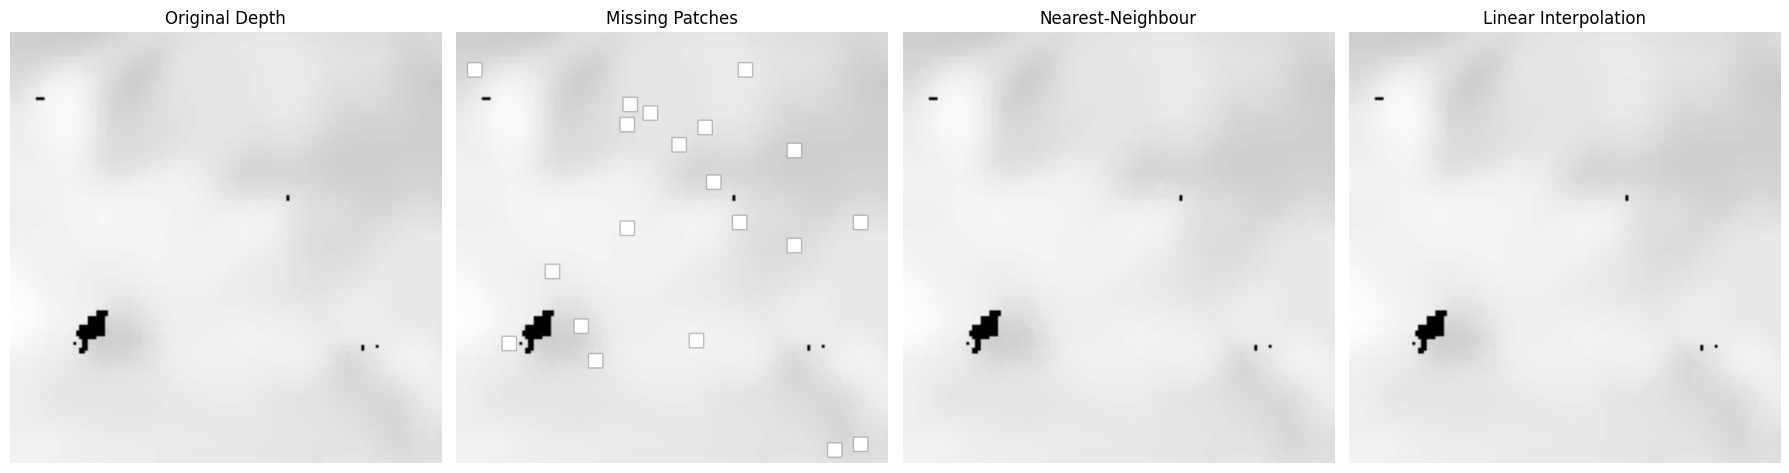

In [34]:
# Use the original depth crop from above
original = depth_crop.copy()

height, width = original.shape

# Create a reproducible random number generator
rng = np.random.default_rng(42)

# Define size and number of missing patches
patch_size = 5
num_patches = 20

# Identify candidate valid pixels
valid_mask = original > 0

# Create a mask identifying pixels to withhold
missing_mask = np.zeros(original.shape, dtype=bool)

# Select patches containing only nonzero measurements
candidate_patches = []

for y in range(height - patch_size + 1):
    for x in range(width - patch_size + 1):

        patch = valid_mask[
            y:y + patch_size,
            x:x + patch_size
        ]

        if np.all(patch):
            candidate_patches.append((y, x))

# Randomise candidate patch locations
rng.shuffle(candidate_patches)

patches_added = 0

for y, x in candidate_patches:

    # Prevent patches from overlapping
    if np.any(
        missing_mask[
            y:y + patch_size,
            x:x + patch_size
        ]
    ):
        continue

    missing_mask[
        y:y + patch_size,
        x:x + patch_size
    ] = True

    patches_added += 1

    if patches_added >= num_patches:
        break

# Create a copy with missing patches
damaged = original.copy()
damaged[missing_mask] = np.nan

# ------------------------------------------------------------
# Prepare interpolation coordinates
# ------------------------------------------------------------

yy, xx = np.indices(original.shape)

# Known measurements exclude zero values and withheld pixels
known_mask = valid_mask & ~missing_mask

known_points = np.column_stack((
    xx[known_mask],
    yy[known_mask]
))

known_values = original[known_mask]

# Locations of missing patches
missing_points = np.column_stack((
    xx[missing_mask],
    yy[missing_mask]
))

true_values = original[missing_mask]

# ------------------------------------------------------------
# Nearest-neighbour interpolation
# ------------------------------------------------------------

nearest_values = griddata(
    known_points,
    known_values,
    missing_points,
    method="nearest"
)

# ------------------------------------------------------------
# Linear interpolation
# ------------------------------------------------------------

linear_values = griddata(
    known_points,
    known_values,
    missing_points,
    method="linear"
)

# Only compare points where both methods return a value
common_mask = (
    np.isfinite(nearest_values) &
    np.isfinite(linear_values)
)

# Calculate RMSE
nearest_rmse = np.sqrt(
    mean_squared_error(
        true_values[common_mask],
        nearest_values[common_mask]
    )
)

linear_rmse = np.sqrt(
    mean_squared_error(
        true_values[common_mask],
        linear_values[common_mask]
    )
)

# ------------------------------------------------------------
# Reconstruct the images
# ------------------------------------------------------------

nearest_reconstruction = damaged.copy()
linear_reconstruction = damaged.copy()

nearest_reconstruction[
    missing_points[:, 1],
    missing_points[:, 0]
] = nearest_values

linear_reconstruction[
    missing_points[:, 1],
    missing_points[:, 0]
] = linear_values

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("MISSING PATCH INTERPOLATION")
print("--------------------------------------")
print("Patch size:", patch_size, "x", patch_size)
print("Patches created:", patches_added)
print("Pixels withheld:", missing_mask.sum())
print("Common valid predictions:", common_mask.sum())
print()
print("Nearest-neighbour RMSE:", round(nearest_rmse, 4))
print("Linear interpolation RMSE:", round(linear_rmse, 4))

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

images = [
    original,
    damaged,
    nearest_reconstruction,
    linear_reconstruction
]

titles = [
    "Original Depth",
    "Missing Patches",
    "Nearest-Neighbour",
    "Linear Interpolation"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=170)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Compare Linear Interpolation with Nearest-Neighbour Interpolation

Patch 3x3: 504 pixels withheld | Nearest RMSE = 0.7224 | Linear RMSE = 0.4903
Patch 5x5: 500 pixels withheld | Nearest RMSE = 0.9445 | Linear RMSE = 0.5397
Patch 10x10: 500 pixels withheld | Nearest RMSE = 1.3653 | Linear RMSE = 0.6071
Patch 15x15: 450 pixels withheld | Nearest RMSE = 0.9345 | Linear RMSE = 0.5888


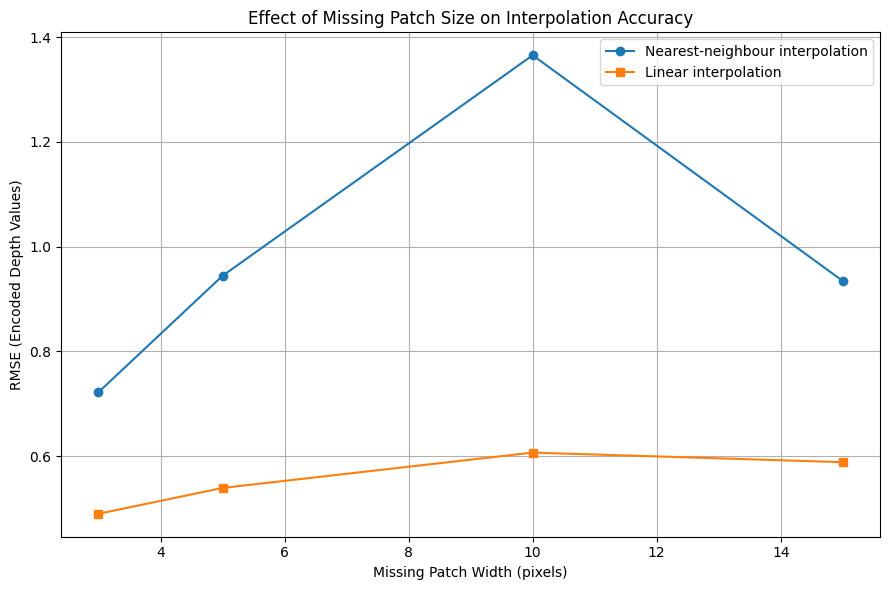

In [35]:
# Use original depth crop
original = depth_crop.copy()

height, width = original.shape

# Patch sizes to investigate
patch_sizes = [3, 5, 10, 15]

# Store numerical results
nearest_errors = []
linear_errors = []

# Create coordinate grids
yy, xx = np.indices(original.shape)

for patch_size in patch_sizes:

    rng = np.random.default_rng(42)

    valid_mask = original > 0
    missing_mask = np.zeros(original.shape, dtype=bool)

    # Identify patches containing valid measurements
    candidate_patches = []

    for y in range(height - patch_size + 1):
        for x in range(width - patch_size + 1):

            patch = valid_mask[
                y:y + patch_size,
                x:x + patch_size
            ]

            if np.all(patch):
                candidate_patches.append((y, x))

    rng.shuffle(candidate_patches)

    # Keep approximately 500 pixels withheld
    num_patches = max(1, round(500 / patch_size**2))

    patches_added = 0

    for y, x in candidate_patches:

        if np.any(
            missing_mask[
                y:y + patch_size,
                x:x + patch_size
            ]
        ):
            continue

        missing_mask[
            y:y + patch_size,
            x:x + patch_size
        ] = True

        patches_added += 1

        if patches_added >= num_patches:
            break

    # Known measurements
    known_mask = valid_mask & ~missing_mask

    known_points = np.column_stack((
        xx[known_mask],
        yy[known_mask]
    ))

    known_values = original[known_mask]

    # Withheld measurements
    missing_points = np.column_stack((
        xx[missing_mask],
        yy[missing_mask]
    ))

    true_values = original[missing_mask]

    # Nearest-neighbour interpolation
    nearest_values = griddata(
        known_points,
        known_values,
        missing_points,
        method="nearest"
    )

    # Linear interpolation
    linear_values = griddata(
        known_points,
        known_values,
        missing_points,
        method="linear"
    )

    # Evaluate only where both methods produce predictions
    common_mask = (
        np.isfinite(nearest_values) &
        np.isfinite(linear_values)
    )

    nearest_rmse = np.sqrt(
        mean_squared_error(
            true_values[common_mask],
            nearest_values[common_mask]
        )
    )

    linear_rmse = np.sqrt(
        mean_squared_error(
            true_values[common_mask],
            linear_values[common_mask]
        )
    )

    nearest_errors.append(nearest_rmse)
    linear_errors.append(linear_rmse)

    print(
        f"Patch {patch_size}x{patch_size}: "
        f"{missing_mask.sum()} pixels withheld | "
        f"Nearest RMSE = {nearest_rmse:.4f} | "
        f"Linear RMSE = {linear_rmse:.4f}"
    )

# ------------------------------------------------------------
# Plot numerical error against patch size
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    patch_sizes,
    nearest_errors,
    marker="o",
    label="Nearest-neighbour interpolation"
)

plt.plot(
    patch_sizes,
    linear_errors,
    marker="s",
    label="Linear interpolation"
)

plt.xlabel("Missing Patch Width (pixels)")
plt.ylabel("RMSE (Encoded Depth Values)")
plt.title("Effect of Missing Patch Size on Interpolation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Save Numerical Results

In [36]:
# Create a results table
interpolation_results = pd.DataFrame({
    "Patch_Size": patch_sizes,
    "Nearest_RMSE": nearest_errors,
    "Linear_RMSE": linear_errors
})

# Save results
results_dir = Path("/content/processed_data")
results_dir.mkdir(parents=True, exist_ok=True)

results_path = results_dir / "interpolation_results.csv"

interpolation_results.to_csv(results_path, index=False)

print("Interpolation results saved!")
print("Location:", results_path)

display(interpolation_results)

Interpolation results saved!
Location: /content/processed_data/interpolation_results.csv


,Patch_Size,Nearest_RMSE,Linear_RMSE
0,3,0.722375,0.490295
1,5,0.944458,0.539650
2,10,1.365284,0.607091
3,15,0.934523,0.588798


### Commit

In [37]:
commit_to_github(
    "Completed numerical interpolation and patch size sensitivity analysis"
)

Successfully committed and pushed to GitHub!
Commit message: Completed numerical interpolation and patch size sensitivity analysis


## Inspect and Align Ground Truth Masks

### Compare direct cropping or resizing to ground truth

Observation: R01N01_Summer_12-40-50
RGB dimensions: (640, 480)
Depth dimensions: (640, 480)
Ground-truth dimensions: (256, 256)


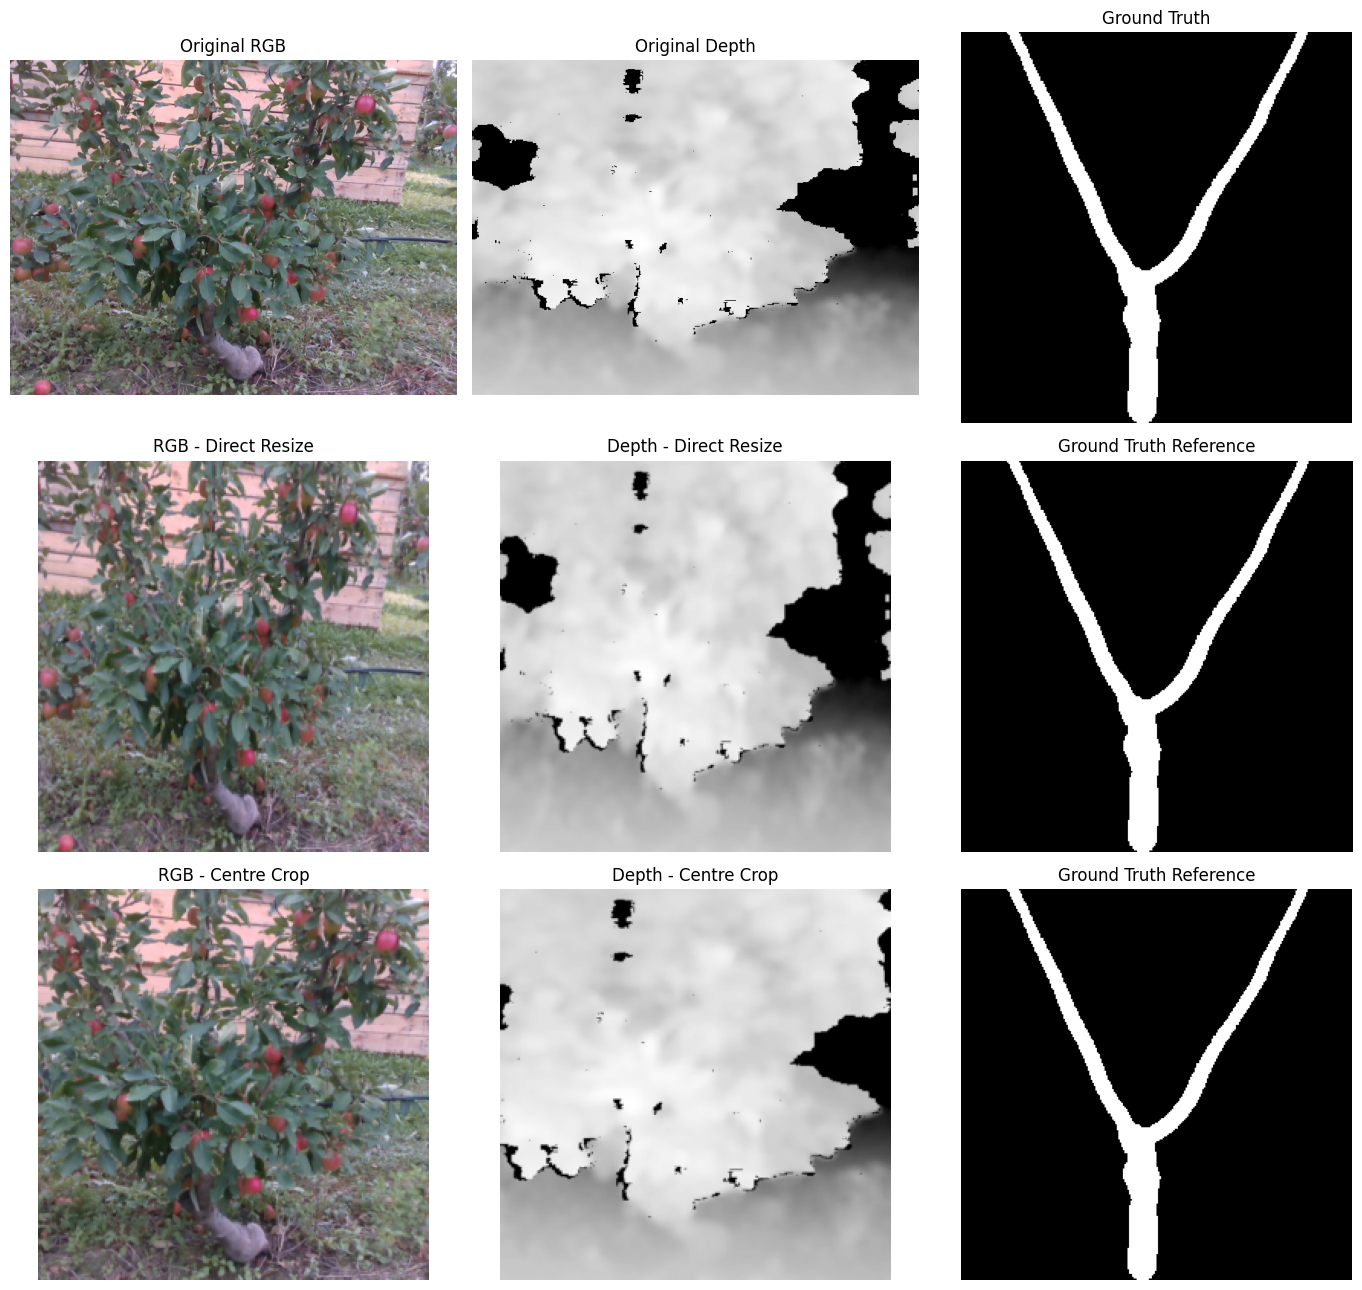

In [38]:
# ============================================================
# INSPECT RGB, DEPTH AND GROUND-TRUTH ALIGNMENT
# ============================================================

from PIL import Image

# Select one summer observation with ground-truth data
example = train_data[
    (train_data["season"] == "Summer") &
    (train_data["has_gt"])
].iloc[0]

# Load the original images
rgb = Image.open(example["rgb_path"]).convert("RGB")
depth = Image.open(example["depth_path"]).convert("L")
gt = Image.open(example["gt_path"]).convert("L")

# Print image dimensions
print("Observation:", example["observation_id"])
print("RGB dimensions:", rgb.size)
print("Depth dimensions:", depth.size)
print("Ground-truth dimensions:", gt.size)

# ------------------------------------------------------------
# Method 1 - Resize RGB and depth directly to 256 x 256
# ------------------------------------------------------------

rgb_resized = rgb.resize(
    (256, 256),
    Image.Resampling.BILINEAR
)

depth_resized = depth.resize(
    (256, 256),
    Image.Resampling.BILINEAR
)

# ------------------------------------------------------------
# Method 2 - Centre-crop to a square, then resize
# ------------------------------------------------------------

def centre_crop_square(image):
    """
    Crop an image to a centred square without stretching it.
    """

    width, height = image.size

    side = min(width, height)

    left = (width - side) // 2
    top = (height - side) // 2

    return image.crop((
        left,
        top,
        left + side,
        top + side
    ))

rgb_cropped = centre_crop_square(rgb).resize(
    (256, 256),
    Image.Resampling.BILINEAR
)

depth_cropped = centre_crop_square(depth).resize(
    (256, 256),
    Image.Resampling.BILINEAR
)

# ------------------------------------------------------------
# Display original images and preprocessing alternatives
# ------------------------------------------------------------

fig, axes = plt.subplots(3, 3, figsize=(14, 13))

# Row 1 - Original images
axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original RGB")

axes[0, 1].imshow(depth, cmap="gray")
axes[0, 1].set_title("Original Depth")

axes[0, 2].imshow(gt, cmap="gray")
axes[0, 2].set_title("Ground Truth")

# Row 2 - Direct resizing
axes[1, 0].imshow(rgb_resized)
axes[1, 0].set_title("RGB - Direct Resize")

axes[1, 1].imshow(depth_resized, cmap="gray")
axes[1, 1].set_title("Depth - Direct Resize")

axes[1, 2].imshow(gt, cmap="gray")
axes[1, 2].set_title("Ground Truth Reference")

# Row 3 - Centre cropping
axes[2, 0].imshow(rgb_cropped)
axes[2, 0].set_title("RGB - Centre Crop")

axes[2, 1].imshow(depth_cropped, cmap="gray")
axes[2, 1].set_title("Depth - Centre Crop")

axes[2, 2].imshow(gt, cmap="gray")
axes[2, 2].set_title("Ground Truth Reference")

# Remove axis labels
for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Overlay ground truth on RGB images

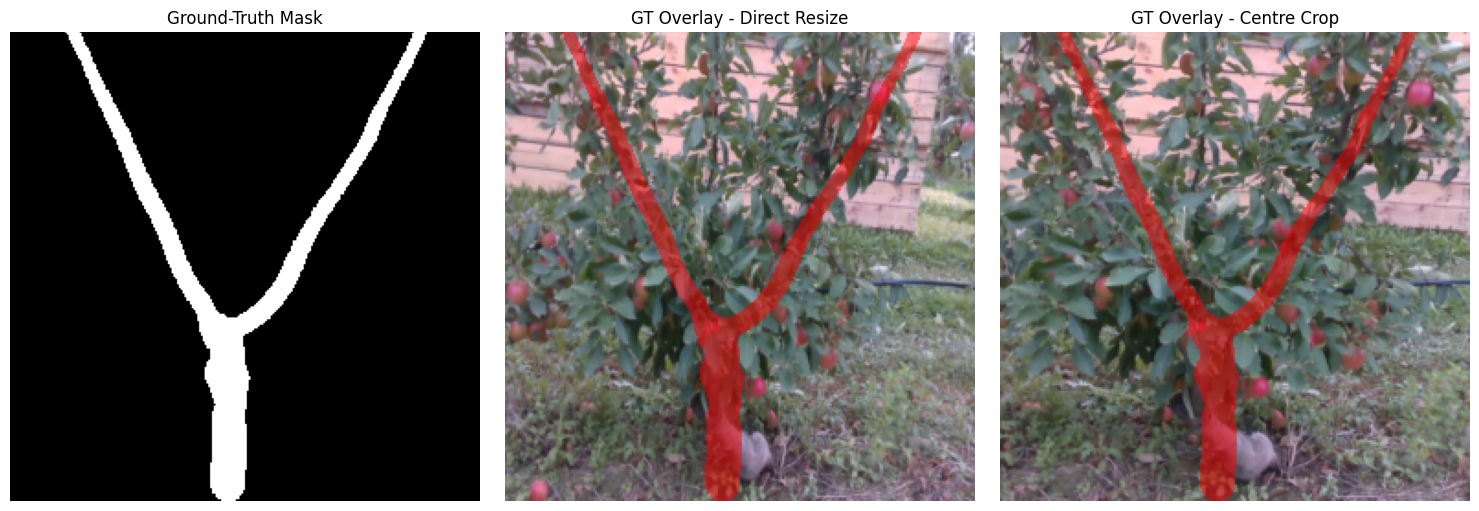

In [39]:
# ============================================================
# VISUALISE GROUND-TRUTH ALIGNMENT
# ============================================================

# Convert images to arrays
rgb_direct_array = np.asarray(rgb_resized)
rgb_crop_array = np.asarray(rgb_cropped)

gt_array = np.asarray(gt)

# Convert GT into a binary mask
gt_binary = gt_array > 127

# ------------------------------------------------------------
# Create overlays
# ------------------------------------------------------------

def create_gt_overlay(rgb_image, gt_mask):
    """
    Overlay the ground-truth tree structure in red
    on top of an RGB image.
    """

    overlay = rgb_image.astype(np.float32).copy()

    # Colour labelled pixels red with partial transparency
    overlay[gt_mask] = (
        0.5 * overlay[gt_mask] +
        0.5 * np.array([255, 0, 0])
    )

    return np.clip(overlay, 0, 255).astype(np.uint8)


# Create overlays for both transformations
direct_overlay = create_gt_overlay(
    rgb_direct_array,
    gt_binary
)

crop_overlay = create_gt_overlay(
    rgb_crop_array,
    gt_binary
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(gt_binary, cmap="gray")
axes[0].set_title("Ground-Truth Mask")

axes[1].imshow(direct_overlay)
axes[1].set_title("GT Overlay - Direct Resize")

axes[2].imshow(crop_overlay)
axes[2].set_title("GT Overlay - Centre Crop")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Inspect multiple trees

In [40]:
# ============================================================
# CHECK ALIGNMENT ACROSS MULTIPLE TREES
# ============================================================

# Select five labelled training observations
samples = train_data[
    train_data["has_gt"]
].sample(
    n=5,
    random_state=42
)

fig, axes = plt.subplots(5, 3, figsize=(12, 20))

for row_index, (_, sample) in enumerate(samples.iterrows()):

    # Load RGB and GT images
    rgb_img = Image.open(
        sample["rgb_path"]
    ).convert("RGB")

    gt_img = Image.open(
        sample["gt_path"]
    ).convert("L")

    # Create binary GT mask
    gt_mask = np.asarray(gt_img) > 127

    # Direct resize
    rgb_direct = np.asarray(
        rgb_img.resize(
            (256, 256),
            Image.Resampling.BILINEAR
        )
    )

    # Centre crop and resize
    rgb_centre = np.asarray(
        centre_crop_square(rgb_img).resize(
            (256, 256),
            Image.Resampling.BILINEAR
        )
    )

    # Create overlays
    overlay_direct = create_gt_overlay(
        rgb_direct,
        gt_mask
    )

    overlay_centre = create_gt_overlay(
        rgb_centre,
        gt_mask
    )

    # Display ground truth
    axes[row_index, 0].imshow(
        gt_mask,
        cmap="gray"
    )

    axes[row_index, 0].set_title(
        f"{sample['tree_id']} - GT"
    )

    # Display direct-resize overlay
    axes[row_index, 1].imshow(
        overlay_direct
    )

    axes[row_index, 1].set_title(
        "Direct Resize"
    )

    # Display centre-crop overlay
    axes[row_index, 2].imshow(
        overlay_centre
    )

    axes[row_index, 2].set_title(
        "Centre Crop"
    )

    for ax in axes[row_index]:
        ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

### Extract tree geometry from ground truths

In [42]:
# ============================================================
# EXTRACT TREE GEOMETRY FROM GROUND-TRUTH MASKS
# ============================================================

def extract_tree_geometry(gt_path):
    """
    Extract basic 2D geometric features from a ground-truth
    tree mask.

    Parameters
    ----------
    gt_path : str or Path
        File path to a ground-truth mask.

    Returns
    -------
    dict
        Dictionary containing the extracted geometry features.
    """

    # Load the ground-truth mask as grayscale
    gt_image = Image.open(gt_path).convert("L")

    # Convert image into a NumPy array
    gt_array = np.asarray(gt_image)

    # Convert to binary mask
    # White pixels represent the annotated tree structure
    tree_mask = gt_array > 127

    # Identify coordinates of all tree pixels
    y_coords, x_coords = np.where(tree_mask)

    # Handle empty masks
    if len(x_coords) == 0:
        return None

    # Calculate the bounding box of the annotated structure
    x_min = np.min(x_coords)
    x_max = np.max(x_coords)

    y_min = np.min(y_coords)
    y_max = np.max(y_coords)

    # Calculate width and height in pixels
    tree_width = x_max - x_min + 1
    tree_height = y_max - y_min + 1

    # Calculate width-to-height ratio
    aspect_ratio = tree_width / tree_height

    # Calculate the total annotated area
    tree_area = np.sum(tree_mask)

    # Normalise measurements by image dimensions
    image_height, image_width = tree_mask.shape

    relative_width = tree_width / image_width
    relative_height = tree_height / image_height

    # Return extracted features
    return {
        "tree_width_px": tree_width,
        "tree_height_px": tree_height,
        "aspect_ratio": aspect_ratio,
        "annotated_area_px": tree_area,
        "relative_width": relative_width,
        "relative_height": relative_height
    }


# ------------------------------------------------------------
# Extract features from all labelled training observations
# ------------------------------------------------------------

geometry_records = []

for _, observation in train_data.iterrows():

    # Skip observations without ground-truth masks
    if not observation["has_gt"]:
        continue

    # Extract geometric measurements
    features = extract_tree_geometry(
        observation["gt_path"]
    )

    if features is None:
        continue

    # Add identifying information
    features["tree_id"] = observation["tree_id"]
    features["observation_id"] = observation["observation_id"]

    geometry_records.append(features)


# Convert results into a DataFrame
geometry_data = pd.DataFrame(geometry_records)

print("STEP 12.4 - TREE GEOMETRY EXTRACTION")
print("----------------------------------")
print("Trees processed:", len(geometry_data))
print()

display(geometry_data.head())

print("\nSummary statistics:")
display(geometry_data.describe())

STEP 12.4 - TREE GEOMETRY EXTRACTION
----------------------------------
Trees processed: 449



,tree_width_px,tree_height_px,aspect_ratio,annotated_area_px,relative_width,relative_height,tree_id,observation_id
0,197,256,0.769531,5215,0.769531,1.0,R01N01,R01N01_Summer_12-40-50
1,151,256,0.589844,5577,0.589844,1.0,R01N02,R01N02_Summer_12-40-59
2,173,256,0.675781,5146,0.675781,1.0,R01N04,R01N04_Summer_12-41-37
3,180,256,0.703125,5303,0.703125,1.0,R01N05,R01N05_Summer_12-41-45
4,173,256,0.675781,5452,0.675781,1.0,R01N06,R01N06_Summer_12-41-52



Summary statistics:


,tree_width_px,tree_height_px,aspect_ratio,annotated_area_px,relative_width,relative_height
count,449.000000,449.0,449.000000,449.000000,449.000000,449.0
mean,175.481069,256.0,0.685473,4937.469933,0.685473,1.0
std,27.459714,0.0,0.107265,434.092742,0.107265,0.0
min,83.000000,256.0,0.324219,3854.000000,0.324219,1.0
25%,159.000000,256.0,0.621094,4651.000000,0.621094,1.0
50%,177.000000,256.0,0.691406,4916.000000,0.691406,1.0
75%,193.000000,256.0,0.753906,5183.000000,0.753906,1.0
max,256.000000,256.0,1.000000,6838.000000,1.000000,1.0


### Visualise variation in tree shape

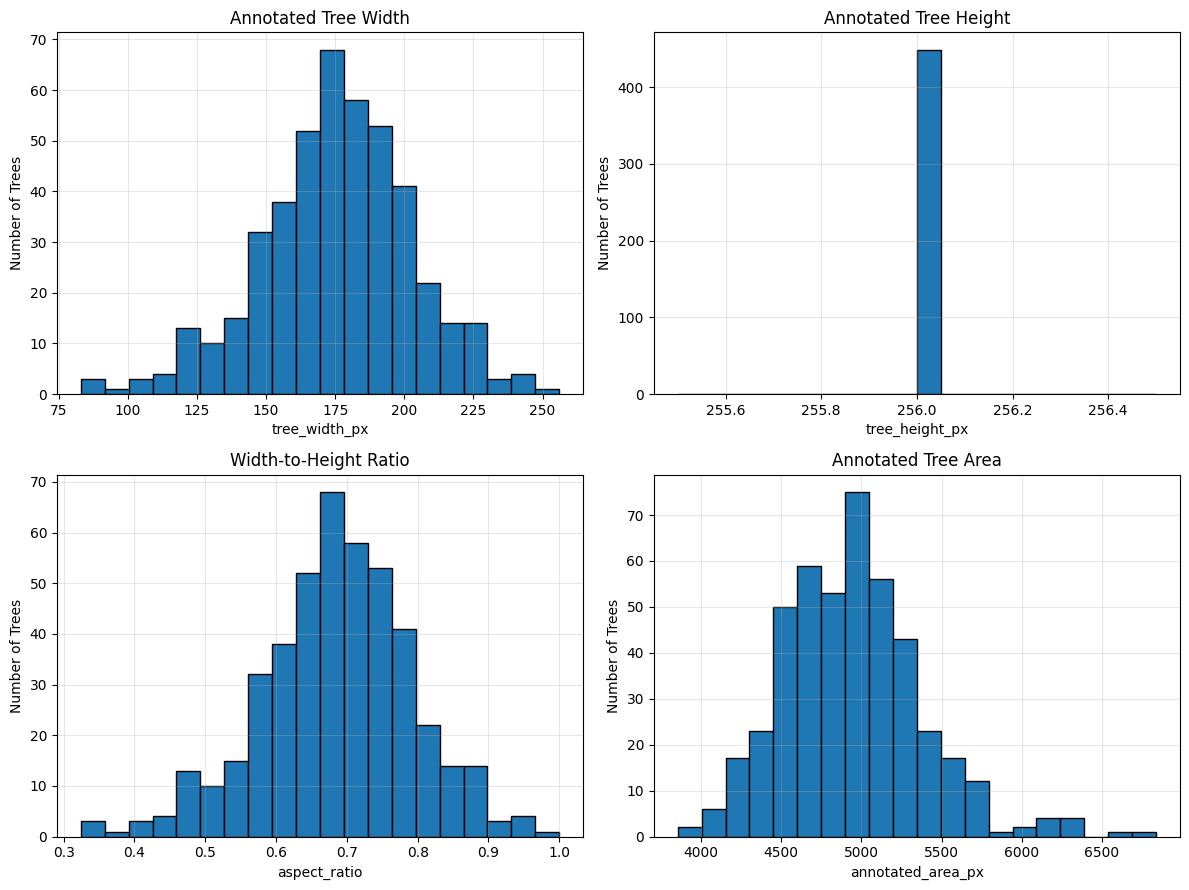

In [43]:
# ============================================================
# STEP 12.5 - VISUALISE TREE GEOMETRY DISTRIBUTIONS
# ============================================================

# Features to investigate
features_to_plot = [
    "tree_width_px",
    "tree_height_px",
    "aspect_ratio",
    "annotated_area_px"
]

titles = [
    "Annotated Tree Width",
    "Annotated Tree Height",
    "Width-to-Height Ratio",
    "Annotated Tree Area"
]

# Create histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature, title in zip(
    axes.flat,
    features_to_plot,
    titles
):

    ax.hist(
        geometry_data[feature],
        bins=20,
        edgecolor="black"
    )

    ax.set_title(title)
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Trees")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Estimate tree branch geometry
The results from above show the different types of shapes of ground truth data. We are not training the model yet, but analysing what kind of data we can use to train a model.

In [44]:
# ============================================================
# ESTIMATE TREE BRANCHING GEOMETRY
# ============================================================

def extract_branch_features(gt_path):
    """
    Estimate branching geometry from a binary GT mask.

    The branching point is approximated by finding where
    the annotated structure becomes wider above the trunk.

    These are image-based measurements, not physical distances.
    """

    # Load the ground-truth mask
    gt = np.asarray(
        Image.open(gt_path).convert("L")
    ) > 127

    height, width = gt.shape

    # Measure the horizontal span of annotated pixels
    # at each row of the image
    row_spans = np.zeros(height)

    for y in range(height):

        x_positions = np.where(gt[y])[0]

        if len(x_positions) > 0:
            row_spans[y] = (
                x_positions.max() - x_positions.min() + 1
            )

    # Estimate typical trunk width using the bottom 15%
    # of the image
    bottom_start = int(height * 0.85)

    trunk_rows = row_spans[bottom_start:]
    trunk_rows = trunk_rows[trunk_rows > 0]

    if len(trunk_rows) == 0:
        return None

    trunk_width = np.median(trunk_rows)

    # Search upwards from the lower trunk.
    # The threshold is an approximate indicator of branching.
    threshold = max(1.8 * trunk_width, trunk_width + 5)

    branch_y = np.nan

    for y in range(height - 1, -1, -1):

        if row_spans[y] > threshold:
            branch_y = y
            break

    # Estimate horizontal branch spread
    y_coords, x_coords = np.where(gt)

    if len(x_coords) == 0:
        return None

    # Use the median trunk position near the bottom
    trunk_pixels_y, trunk_pixels_x = np.where(
        gt[bottom_start:]
    )

    if len(trunk_pixels_x) == 0:
        return None

    trunk_centre = np.median(trunk_pixels_x)

    # Calculate maximum spread on either side
    left_spread = max(
        0,
        trunk_centre - np.min(x_coords)
    )

    right_spread = max(
        0,
        np.max(x_coords) - trunk_centre
    )

    # Calculate asymmetry
    total_spread = left_spread + right_spread

    asymmetry = (
        abs(left_spread - right_spread) / total_spread
        if total_spread > 0 else 0
    )

    return {
        "trunk_width_px": trunk_width,
        "branch_point_y_px": branch_y,
        "branch_point_relative": (
            branch_y / height
            if not np.isnan(branch_y) else np.nan
        ),
        "left_spread_px": left_spread,
        "right_spread_px": right_spread,
        "branch_asymmetry": asymmetry
    }


# ------------------------------------------------------------
# Apply to all labelled training observations
# ------------------------------------------------------------

branch_records = []

for _, observation in train_data.iterrows():

    if not observation["has_gt"]:
        continue

    features = extract_branch_features(
        observation["gt_path"]
    )

    if features is None:
        continue

    features["observation_id"] = observation["observation_id"]
    features["tree_id"] = observation["tree_id"]

    branch_records.append(features)

branch_data = pd.DataFrame(branch_records)

print("BRANCH GEOMETRY")
print("---------------------------")
print("Trees processed:", len(branch_data))

display(branch_data.head())

print("\nSummary statistics:")
display(branch_data.describe())

STEP 12.6 - BRANCH GEOMETRY
---------------------------
Trees processed: 449


,trunk_width_px,branch_point_y_px,branch_point_relative,left_spread_px,right_spread_px,branch_asymmetry,observation_id,tree_id
0,19.0,159,0.621094,89.0,107.0,0.091837,R01N01_Summer_12-40-50,R01N01
1,37.0,181,0.707031,77.0,73.0,0.026667,R01N02_Summer_12-40-59,R01N02
2,24.0,176,0.687500,56.0,116.0,0.348837,R01N04_Summer_12-41-37,R01N04
3,30.0,166,0.648438,109.0,70.0,0.217877,R01N05_Summer_12-41-45,R01N05
4,24.0,193,0.753906,84.0,88.0,0.023256,R01N06_Summer_12-41-52,R01N06



Summary statistics:


,trunk_width_px,branch_point_y_px,branch_point_relative,left_spread_px,right_spread_px,branch_asymmetry
count,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000
mean,20.180401,174.995546,0.683576,87.368597,87.112472,0.178656
std,4.875318,19.798877,0.077339,23.200251,23.373332,0.140645
min,11.000000,111.000000,0.433594,13.000000,21.000000,0.000000
25%,17.000000,162.000000,0.632812,73.000000,73.000000,0.073446
50%,19.000000,175.000000,0.683594,89.000000,86.000000,0.145946
75%,23.000000,188.000000,0.734375,103.000000,101.000000,0.254438
max,44.000000,229.000000,0.894531,143.500000,148.000000,0.697674


### Visualise branching plots

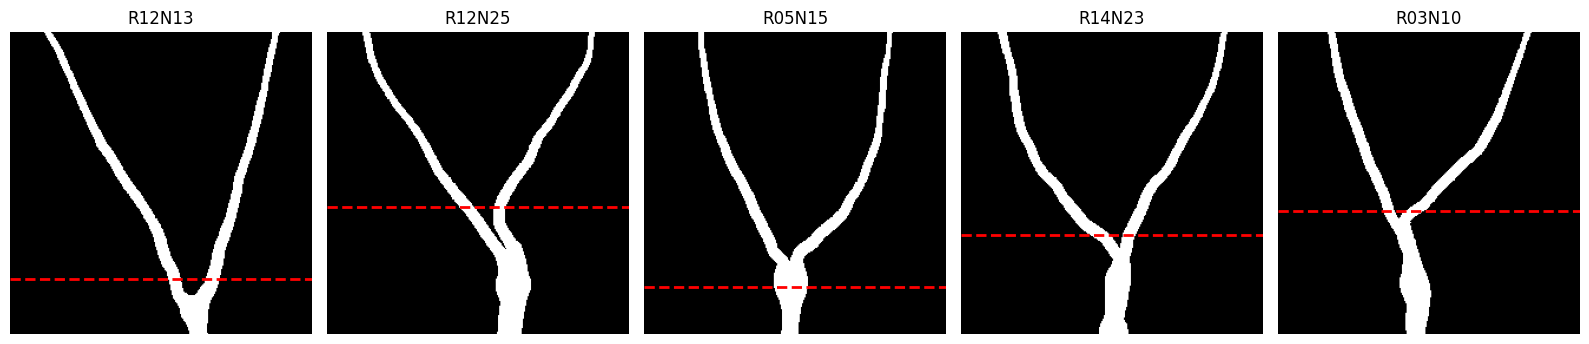

In [45]:
# ============================================================
# VISUALISE ESTIMATED BRANCHING POINTS
# ============================================================

# Select five training observations
samples = train_data[
    train_data["has_gt"]
].sample(n=5, random_state=42)

fig, axes = plt.subplots(1, 5, figsize=(16, 5))

for ax, (_, observation) in zip(axes, samples.iterrows()):

    # Load GT mask
    gt = np.asarray(
        Image.open(observation["gt_path"]).convert("L")
    )

    # Extract estimated features
    features = extract_branch_features(
        observation["gt_path"]
    )

    ax.imshow(gt, cmap="gray")

    if features is not None:

        branch_y = features["branch_point_y_px"]

        if not np.isnan(branch_y):

            # Draw estimated branching height
            ax.axhline(
                branch_y,
                color="red",
                linestyle="--",
                linewidth=2
            )

    ax.set_title(observation["tree_id"])
    ax.axis("off")

plt.tight_layout()
plt.show()

### Validate extracted geometry features

In [46]:
# ============================================================
# VALIDATE EXTRACTED GEOMETRY FEATURES
# ============================================================

# Recalculate branch asymmetry directly from the saved spreads
branch_data["branch_asymmetry"] = (
    abs(
        branch_data["left_spread_px"] -
        branch_data["right_spread_px"]
    ) /
    (
        branch_data["left_spread_px"] +
        branch_data["right_spread_px"]
    )
)

# Check that no values are missing
print("Missing values:")
print(branch_data.isnull().sum())

# Check that branching positions fall within the image
valid_branch_points = branch_data[
    "branch_point_y_px"
].between(0, 255).all()

print("\nAll branching points within image:",
      valid_branch_points)

# Check that asymmetry is between 0 and 1
valid_asymmetry = branch_data[
    "branch_asymmetry"
].between(0, 1).all()

print("All asymmetry values valid:",
      valid_asymmetry)

# Check that each tree appears only once
print("Unique trees:", branch_data["tree_id"].nunique())
print("Total observations:", len(branch_data))

# Display corrected summary statistics
display(branch_data.describe())

Missing values:
trunk_width_px           0
branch_point_y_px        0
branch_point_relative    0
left_spread_px           0
right_spread_px          0
branch_asymmetry         0
observation_id           0
tree_id                  0
dtype: int64

All branching points within image: True
All asymmetry values valid: True
Unique trees: 449
Total observations: 449


,trunk_width_px,branch_point_y_px,branch_point_relative,left_spread_px,right_spread_px,branch_asymmetry
count,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000
mean,20.180401,174.995546,0.683576,87.368597,87.112472,0.178656
std,4.875318,19.798877,0.077339,23.200251,23.373332,0.140645
min,11.000000,111.000000,0.433594,13.000000,21.000000,0.000000
25%,17.000000,162.000000,0.632812,73.000000,73.000000,0.073446
50%,19.000000,175.000000,0.683594,89.000000,86.000000,0.145946
75%,23.000000,188.000000,0.734375,103.000000,101.000000,0.254438
max,44.000000,229.000000,0.894531,143.500000,148.000000,0.697674


### Combine geometry data with previously saved table

In [47]:
# ============================================================
# COMBINE AND SAVE TREE GEOMETRY FEATURES
# ============================================================

from pathlib import Path

# Merge using observation ID and tree ID
tree_features = pd.merge(
    geometry_data,
    branch_data,
    on=["observation_id", "tree_id"],
    how="inner",
    validate="one_to_one"
)

# Select informative geometry features
selected_columns = [
    "tree_id",
    "observation_id",
    "tree_width_px",
    "annotated_area_px",
    "trunk_width_px",
    "branch_point_y_px",
    "left_spread_px",
    "right_spread_px",
    "branch_asymmetry"
]

tree_features = tree_features[selected_columns]

# Confirm expected number of training trees
assert len(tree_features) == 449

# Save results
output_dir = Path("/content/processed_data")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "tree_geometry_features.csv"

tree_features.to_csv(output_path, index=False)

print("Tree geometry features saved successfully!")
print("Location:", output_path)
print("Number of trees:", len(tree_features))

display(tree_features.head())

Tree geometry features saved successfully!
Location: /content/processed_data/tree_geometry_features.csv
Number of trees: 449


,tree_id,observation_id,tree_width_px,annotated_area_px,trunk_width_px,branch_point_y_px,left_spread_px,right_spread_px,branch_asymmetry
0,R01N01,R01N01_Summer_12-40-50,197,5215,19.0,159,89.0,107.0,0.091837
1,R01N02,R01N02_Summer_12-40-59,151,5577,37.0,181,77.0,73.0,0.026667
2,R01N04,R01N04_Summer_12-41-37,173,5146,24.0,176,56.0,116.0,0.348837
3,R01N05,R01N05_Summer_12-41-45,180,5303,30.0,166,109.0,70.0,0.217877
4,R01N06,R01N06_Summer_12-41-52,173,5452,24.0,193,84.0,88.0,0.023256


### Commit to Github

In [48]:
commit_to_github("Completed ground truth mask analysis.")

Successfully committed and pushed to GitHub!
Commit message: Completed ground truth mask analysis.


## Prepare Machine Learning Inputs

### Extract training image features

In [51]:
# ============================================================
# EXTRACT RGB AND DEPTH IMAGE FEATURES
# ============================================================

def extract_image_features(rgb_path, depth_path):
    """
    Extract numerical features from an RGB image and its
    corresponding encoded depth image.

    These features will be used as inputs for machine
    learning regression.

    Depth values are treated as encoded image values,
    not physical distances.
    """

    # Load RGB image as a NumPy array
    rgb = np.asarray(
        Image.open(rgb_path).convert("RGB"),
        dtype=np.float32
    )

    # Load encoded depth image
    depth_image = np.asarray(
        Image.open(depth_path)
    )

    # Depth images have identical RGB channels.
    # Use the first channel to obtain a 2D array.
    if depth_image.ndim == 3:
        depth = depth_image[:, :, 0].astype(np.float32)
    else:
        depth = depth_image.astype(np.float32)

    # Separate RGB colour channels
    red = rgb[:, :, 0]
    green = rgb[:, :, 1]
    blue = rgb[:, :, 2]

    # Identify valid encoded depth pixels
    valid_depth = depth > 0

    # Calculate depth statistics using valid pixels only
    if np.any(valid_depth):
        depth_mean = np.mean(depth[valid_depth])
        depth_std = np.std(depth[valid_depth])
        depth_min = np.min(depth[valid_depth])
        depth_max = np.max(depth[valid_depth])
    else:
        depth_mean = 0
        depth_std = 0
        depth_min = 0
        depth_max = 0

    # Calculate proportion of zero-valued depth pixels
    invalid_depth_fraction = np.mean(~valid_depth)

    # Return numerical image features
    return {
        "red_mean": np.mean(red),
        "green_mean": np.mean(green),
        "blue_mean": np.mean(blue),

        "red_std": np.std(red),
        "green_std": np.std(green),
        "blue_std": np.std(blue),

        "depth_mean": depth_mean,
        "depth_std": depth_std,
        "depth_min": depth_min,
        "depth_max": depth_max,

        "invalid_depth_fraction": invalid_depth_fraction
    }


# ------------------------------------------------------------
# Extract features from labelled summer training observations
# ------------------------------------------------------------

image_feature_records = []

summer_train = train_data[
    (train_data["season"] == "Summer") &
    (train_data["has_gt"])
]

for _, observation in summer_train.iterrows():

    # Extract RGB and depth statistics
    features = extract_image_features(
        observation["rgb_path"],
        observation["depth_path"]
    )

    # Store identifying information
    features["tree_id"] = observation["tree_id"]
    features["observation_id"] = observation["observation_id"]

    image_feature_records.append(features)


# Convert extracted features into a DataFrame
image_features = pd.DataFrame(image_feature_records)

print("IMAGE FEATURE EXTRACTION")
print("-----------------------------------")
print("Training observations processed:", len(image_features))

display(image_features.head())

print("\nSummary statistics:")
display(image_features.describe())

IMAGE FEATURE EXTRACTION
-----------------------------------
Training observations processed: 449


,red_mean,green_mean,blue_mean,red_std,green_std,blue_std,depth_mean,depth_std,depth_min,depth_max,invalid_depth_fraction,tree_id,observation_id
0,115.350418,113.570160,109.573410,46.584454,38.422634,42.102272,132.444305,26.199760,1.0,169.0,0.118356,R01N01,R01N01_Summer_12-40-50
1,112.368713,122.933670,116.427269,47.516209,39.279301,43.292740,137.498642,18.737856,2.0,165.0,0.048304,R01N02,R01N02_Summer_12-40-59
2,114.959099,112.006760,108.816742,43.942898,41.804852,45.787510,127.898956,25.228827,1.0,161.0,0.067448,R01N04,R01N04_Summer_12-41-37
3,108.214821,102.909729,101.872047,37.337646,36.222198,38.462910,121.614937,25.305283,1.0,167.0,0.098223,R01N05,R01N05_Summer_12-41-45
4,111.793427,108.150635,106.596382,42.120201,41.037655,43.308964,122.136841,30.629168,1.0,161.0,0.121507,R01N06,R01N06_Summer_12-41-52



Summary statistics:


,red_mean,green_mean,blue_mean,red_std,green_std,blue_std,depth_mean,depth_std,depth_min,depth_max,invalid_depth_fraction
count,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000
mean,117.525833,113.691887,111.337898,35.701721,32.803471,37.022644,124.328056,35.154045,1.812918,165.786194,0.161568
std,5.038096,4.655224,5.391885,3.702901,3.693696,3.893145,8.261635,5.230711,5.717762,7.642905,0.063475
min,83.473236,83.078438,65.049538,25.876078,24.391621,27.494864,97.418236,12.986691,1.000000,144.000000,0.007679
25%,115.255219,111.836861,109.159088,33.308243,30.340239,34.562027,119.018089,32.058109,1.000000,161.000000,0.116354
50%,117.860130,113.731522,111.393166,35.417995,32.434578,36.837105,123.464851,35.276348,1.000000,166.000000,0.154186
75%,119.782837,115.771095,114.014610,37.816277,34.958767,39.045452,130.015350,38.735344,1.000000,170.000000,0.203034
max,148.178177,143.535553,142.827591,50.681232,48.334602,62.668179,157.782898,50.508377,84.000000,193.000000,0.446410


### Prepare training dataset

In [50]:
# ============================================================
# CREATE MACHINE LEARNING TRAINING DATASET
# ============================================================

# Combine input features with reference geometry measurements
ml_train_data = pd.merge(
    image_features,
    tree_features,
    on=["tree_id", "observation_id"],
    how="inner",
    validate="one_to_one"
)

# Check dataset size
assert len(ml_train_data) == 449

# Identify the input features
input_columns = [
    "red_mean",
    "green_mean",
    "blue_mean",
    "red_std",
    "green_std",
    "blue_std",
    "depth_mean",
    "depth_std",
    "depth_min",
    "depth_max",
    "invalid_depth_fraction"
]

# Identify the geometry measurements to predict
target_columns = [
    "tree_width_px",
    "annotated_area_px",
    "trunk_width_px",
    "branch_point_y_px",
    "left_spread_px",
    "right_spread_px"
]

# Create input and target arrays
X_train = ml_train_data[input_columns].to_numpy()
y_train = ml_train_data[target_columns].to_numpy()

print("MACHINE LEARNING DATASET")
print("------------------------------------")
print("Input array shape:", X_train.shape)
print("Target array shape:", y_train.shape)

# Save the combined dataset
from pathlib import Path

output_dir = Path("/content/processed_data")
output_dir.mkdir(parents=True, exist_ok=True)

ml_train_data.to_csv(
    output_dir / "ml_training_data.csv",
    index=False
)

print("\nMachine learning training dataset saved!")

MACHINE LEARNING DATASET
------------------------------------
Input array shape: (449, 11)
Target array shape: (449, 6)

Machine learning training dataset saved!


### Prepare validation dataset

In [52]:

# ============================================================
# PREPARE VALIDATION DATASET
# ============================================================

# Select summer validation observations with ground truth
summer_validation = validation_data[
    (validation_data["season"] == "Summer") &
    (validation_data["has_gt"])
].copy()

# Extract the same 11 RGB-depth features used for training
validation_records = []

for _, observation in summer_validation.iterrows():

    features = extract_image_features(
        observation["rgb_path"],
        observation["depth_path"]
    )

    features["tree_id"] = observation["tree_id"]
    features["observation_id"] = observation["observation_id"]

    validation_records.append(features)

validation_image_features = pd.DataFrame(validation_records)

print("Validation observations:", len(validation_image_features))

# IMPORTANT:
# We need ground-truth geometry for the validation trees.
# The earlier tree_features table only contains training trees,
# so we cannot merge validation rows with that table.

print("\nValidation image features:")
display(validation_image_features.head())

# Check that no physical tree appears in both datasets
training_ids = set(ml_train_data["tree_id"])
validation_ids = set(validation_image_features["tree_id"])

assert training_ids.isdisjoint(validation_ids), \
    "Data leakage detected: a tree appears in both sets!"

assert len(validation_image_features) == 113

print("\nValidation image extraction successful.")
print("No training/validation tree overlap.")


Validation observations: 113

Validation image features:


,red_mean,green_mean,blue_mean,red_std,green_std,blue_std,depth_mean,depth_std,depth_min,depth_max,invalid_depth_fraction,tree_id,observation_id
0,105.833595,119.125237,112.418007,45.477028,38.619102,42.433960,134.467651,20.327839,1.0,161.0,0.060703,R01N03,R01N03_Summer_12-41-4
1,117.830925,112.817474,112.179314,37.085255,36.644997,38.675919,123.144615,31.402756,1.0,160.0,0.105208,R01N07,R01N07_Summer_12-41-57
2,116.936134,111.652710,110.921211,38.179352,37.964638,40.290031,122.302795,32.024319,1.0,169.0,0.150840,R01N10,R01N10_Summer_12-42-12
3,113.657799,108.799469,109.079605,37.193050,36.638016,38.850494,128.435715,34.359844,1.0,168.0,0.100788,R01N11,R01N11_Summer_12-42-17
4,113.674767,109.792824,111.772835,39.765202,36.605923,40.273010,116.346733,31.877420,1.0,158.0,0.142318,R01N16,R01N16_Summer_12-43-4



Validation image extraction successful.
No training/validation tree overlap.


### Standardise both training and validation inputs

In [54]:

# ============================================================
# STANDARDISE MACHINE LEARNING INPUTS
# ============================================================

# Create the standardisation model
input_scaler = StandardScaler()

# Fit ONLY on training data to avoid data leakage
X_train_scaled = input_scaler.fit_transform(X_train)

# Apply the same transformation to validation inputs
X_validation = validation_image_features[
    input_columns
].to_numpy()

X_validation_scaled = input_scaler.transform(X_validation)

# Check dimensions
print("STANDARDISATION")
print("-----------------------------------")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_validation_scaled.shape)

# Confirm no invalid numerical values were introduced
assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_validation_scaled).all()

print("\nStandardisation completed successfully!")


STANDARDISATION
-----------------------------------
Scaled training shape: (449, 11)
Scaled validation shape: (113, 11)

Standardisation completed successfully!


### Confirm existing geometry extraction functions

In [56]:

# ============================================================
# CHECK EXISTING GEOMETRY EXTRACTION FUNCTIONS
# ============================================================

import inspect

# Find functions previously defined in the notebook
geometry_functions = [
    name for name, obj in globals().items()
    if inspect.isfunction(obj)
    and any(word in name.lower()
            for word in ["geometry", "branch", "feature", "mask"])
]

print("Available feature and geometry functions:")
for name in geometry_functions:
    print("-", name)

# Check the exact target columns used for training
print("\nTraining target columns:")
print(list(target_columns))

# Check validation ground-truth availability
print("\nValidation trees with ground truth:")
print(summer_validation["gt_path"].notna().sum())

print("\nExample validation mask:")
print(summer_validation.iloc[0]["gt_path"])

# Display the function definitions used
print("EXTRACT TREE GEOMETRY")
print("=" * 50)
print(inspect.getsource(extract_tree_geometry))

print("\nEXTRACT BRANCH FEATURES")
print("=" * 50)
print(inspect.getsource(extract_branch_features))

# Confirm the six target measurements
print("\nTARGET COLUMNS")
print("=" * 50)

for column in target_columns:
    print("-", column)


Available feature and geometry functions:
- extract_tree_geometry
- extract_branch_features
- extract_image_features

Training target columns:
['tree_width_px', 'annotated_area_px', 'trunk_width_px', 'branch_point_y_px', 'left_spread_px', 'right_spread_px']

Validation trees with ground truth:
113

Example validation mask:
/content/tree_dataset/Dataset (With Summer GT)/R01N03_Summer_GT-12-41-4.png
EXTRACT TREE GEOMETRY
def extract_tree_geometry(gt_path):
    """
    Extract basic 2D geometric features from a ground-truth
    tree mask.

    Parameters
    ----------
    gt_path : str or Path
        File path to a ground-truth mask.

    Returns
    -------
    dict
        Dictionary containing the extracted geometry features.
    """

    # Load the ground-truth mask as grayscale
    gt_image = Image.open(gt_path).convert("L")

    # Convert image into a NumPy array
    gt_array = np.asarray(gt_image)

    # Convert to binary mask
    # White pixels represent the annotated tree struc

### Extract validation ground truth geometry

In [57]:

# ============================================================
# EXTRACT VALIDATION GROUND-TRUTH GEOMETRY
# ============================================================

# Store the geometry measurements for each validation tree
validation_geometry_records = []

# Process the 113 validation trees with ground-truth masks
for _, observation in summer_validation.iterrows():

    gt_path = observation["gt_path"]

    # Extract the basic 2D tree geometry
    tree_geometry = extract_tree_geometry(gt_path)

    # Extract the branching geometry
    branch_geometry = extract_branch_features(gt_path)

    # Skip masks where geometry could not be extracted
    if tree_geometry is None or branch_geometry is None:
        print("Could not process:", gt_path)
        continue

    # Combine the two sets of measurements
    geometry = {
        **tree_geometry,
        **branch_geometry
    }

    # Preserve the observation identifiers for matching
    geometry["tree_id"] = observation["tree_id"]
    geometry["observation_id"] = observation["observation_id"]

    validation_geometry_records.append(geometry)

# Convert measurements into a DataFrame
validation_geometry = pd.DataFrame(validation_geometry_records)

print("VALIDATION GEOMETRY")
print("-----------------------------------")
print("Validation trees processed:", len(validation_geometry))

# Display the first five observations
display(validation_geometry.head())

# Check that all six targets were extracted
print("\nMissing target values:")
print(validation_geometry[target_columns].isna().sum())


VALIDATION GEOMETRY
-----------------------------------
Validation trees processed: 113


,tree_width_px,tree_height_px,aspect_ratio,annotated_area_px,relative_width,relative_height,trunk_width_px,branch_point_y_px,branch_point_relative,left_spread_px,right_spread_px,branch_asymmetry,tree_id,observation_id
0,145,256,0.566406,4643,0.566406,1.0,27.0,208,0.812500,79.0,65.0,0.097222,R01N03,R01N03_Summer_12-41-4
1,211,256,0.824219,4997,0.824219,1.0,17.0,168,0.656250,110.0,100.0,0.047619,R01N07,R01N07_Summer_12-41-57
2,166,256,0.648438,5286,0.648438,1.0,28.0,162,0.632812,86.0,79.0,0.042424,R01N10,R01N10_Summer_12-42-12
3,188,256,0.734375,5239,0.734375,1.0,34.0,179,0.699219,53.0,134.0,0.433155,R01N11,R01N11_Summer_12-42-17
4,153,256,0.597656,5112,0.597656,1.0,21.0,153,0.597656,87.0,65.0,0.144737,R01N16,R01N16_Summer_12-43-4



Missing target values:
tree_width_px        0
annotated_area_px    0
trunk_width_px       0
branch_point_y_px    0
left_spread_px       0
right_spread_px      0
dtype: int64


### Create Validation target array

In [58]:

# ============================================================
# CREATE VALIDATION TARGET ARRAY
# ============================================================

# Match image features to their ground-truth geometry
validation_complete = validation_image_features.merge(
    validation_geometry[
        ["observation_id"] + target_columns
    ],
    on="observation_id",
    how="inner",
    validate="one_to_one"
)

# Ensure all 113 validation observations were matched
assert len(validation_complete) == len(validation_image_features), \
    "Some validation observations are missing geometry targets."

# Extract input features in the same order as training
X_validation = validation_complete[
    input_columns
].to_numpy()

# Extract the six reference geometry measurements
y_validation = validation_complete[
    target_columns
].to_numpy()

# Apply the existing training-fitted scaler
# Do not fit a new scaler on validation data
X_validation_scaled = input_scaler.transform(X_validation)

# Confirm that the arrays contain valid numbers
assert np.isfinite(X_validation_scaled).all()
assert np.isfinite(y_validation).all()

print("STEP 13.8 - VALIDATION DATASET")
print("-----------------------------------")
print("Training inputs:", X_train_scaled.shape)
print("Training targets:", y_train.shape)
print("Validation inputs:", X_validation_scaled.shape)
print("Validation targets:", y_validation.shape)

print("\nValidation dataset prepared successfully!")

# Save the validation dataset for later use
output_dir = Path("/content/processed_data")
output_dir.mkdir(parents=True, exist_ok=True)

validation_complete.to_csv(
    output_dir / "ml_validation_data.csv",
    index=False
)

print("Validation dataset saved to:", output_dir)


STEP 13.8 - VALIDATION DATASET
-----------------------------------
Training inputs: (449, 11)
Training targets: (449, 6)
Validation inputs: (113, 11)
Validation targets: (113, 6)

Validation dataset prepared successfully!
Validation dataset saved to: /content/processed_data


In [ ]:
commit_to_github("Training and ")